In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from google.colab.patches import cv2_imshow
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ruta_imagen = '/content/drive/MyDrive/RADIOGRAFIA_NORMAL.jpg'

In [ ]:
ruta_imagen2 = '/content/drive/MyDrive/IMAGEN_PIXEL.png'

In [ ]:
img=cv2.imread(ruta_imagen)

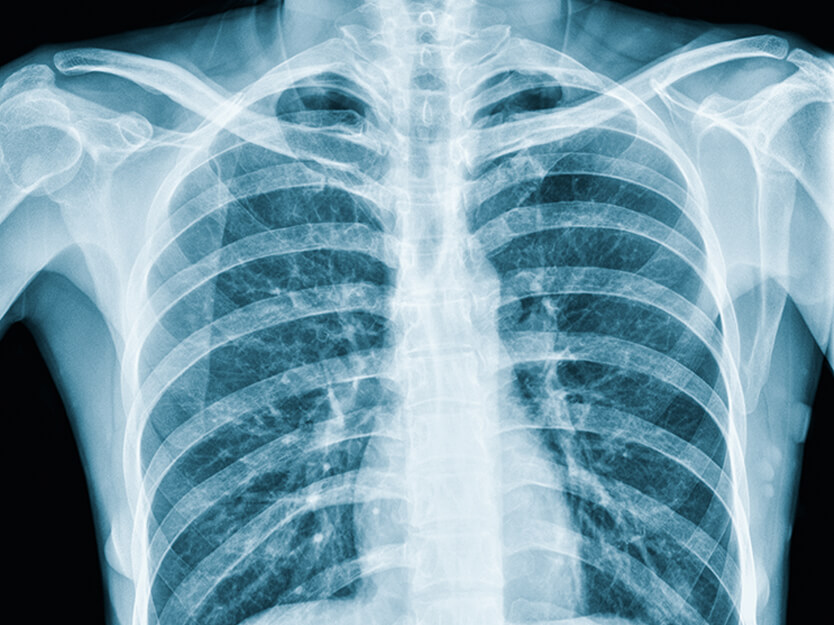

In [ ]:
cv2_imshow(img)

In [ ]:
plt.imshow(img)
plt.show()

NameError: name 'plt' is not defined

In [ ]:
img2 = cv2.imread(ruta_imagen2)

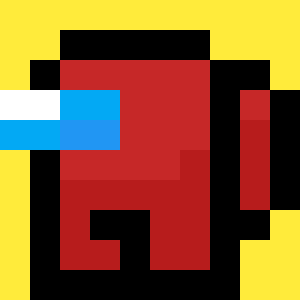

In [ ]:
cv2_imshow(img2)

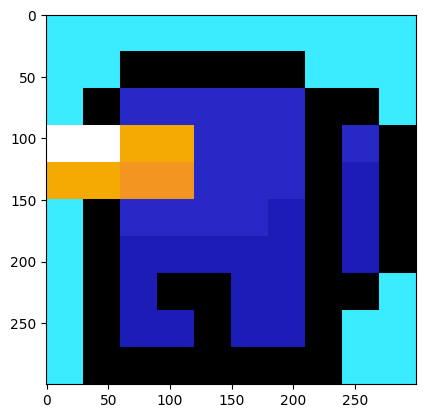

In [ ]:
plt.imshow(img2)
plt.show()

In [ ]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_rgb.shape

(625, 834, 3)

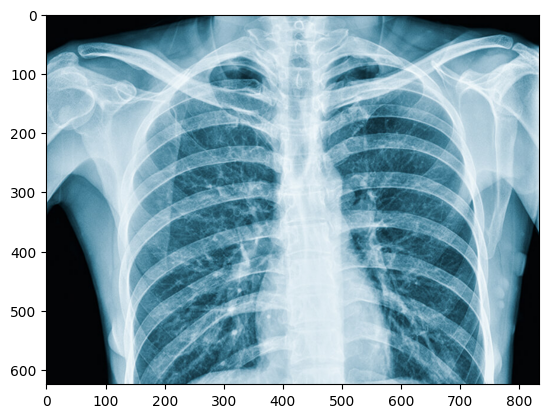

In [ ]:
plt.imshow(img_rgb)
plt.show()

In [ ]:
img_rgb2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img_rgb2.shape

(300, 300, 3)

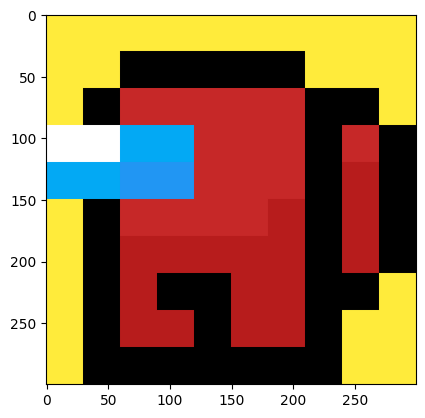

In [ ]:
plt.imshow(img_rgb2)
plt.show()

In [ ]:
canal_rojo = img_rgb[:, :, 0]
canal_verde = img_rgb[:, :, 1]
canal_azul = img_rgb[:, :, 2]

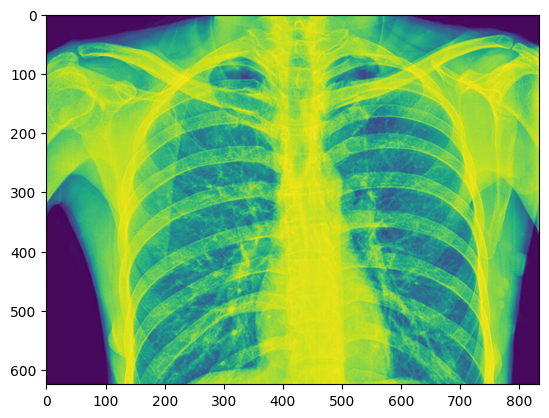

In [ ]:
plt.imshow(canal_azul)
plt.show()

In [ ]:
canal_rojo2 = img_rgb2[:, :, 0]
canal_verde2 = img_rgb2[:, :, 1]
canal_azul2 = img_rgb2[:, :, 2]

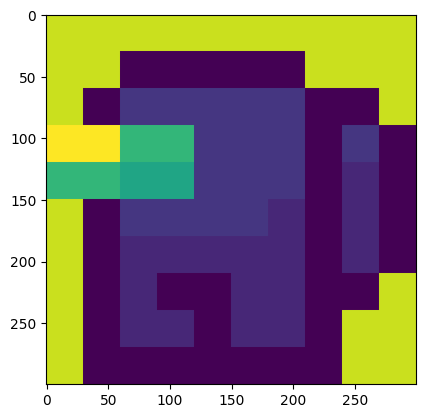

In [ ]:
plt.imshow(canal_verde2)
plt.show()

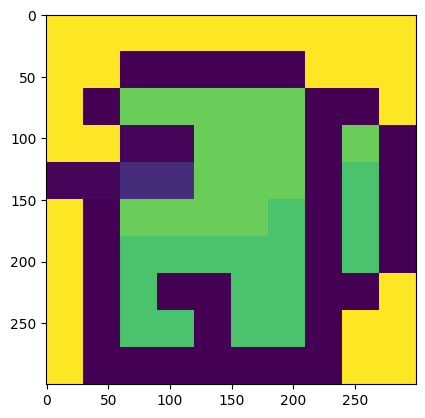

In [ ]:
plt.imshow(canal_rojo2)
plt.show()

<h1>APLICAMOS NUESTROS FILTROS</h1>

In [ ]:
image_gray = cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)

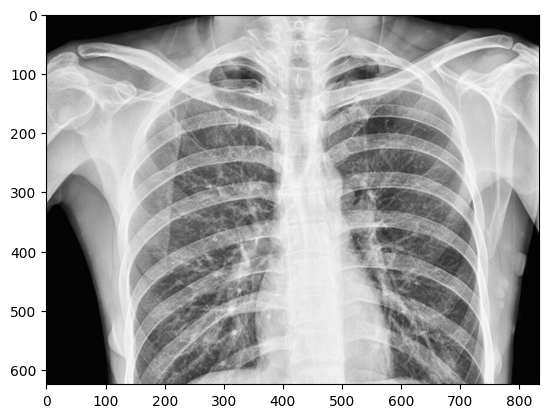

In [ ]:
plt.imshow(image_gray,cmap='gray')
plt.show()

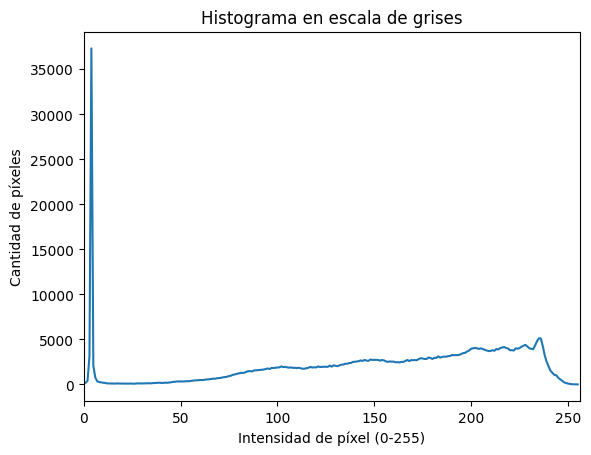

In [ ]:
# graficamos el histograma
hist = cv2.calcHist([image_gray], [0], None, [256], [0, 256])
plt.figure()
plt.title("Histograma en escala de grises")
plt.xlabel("Intensidad de píxel (0-255)")
plt.ylabel("Cantidad de píxeles")
plt.plot(hist)
plt.xlim([0, 256])
plt.show()

In [ ]:
image_gray2 = cv2.cvtColor(img2,cv2.COLOR_RGB2GRAY)

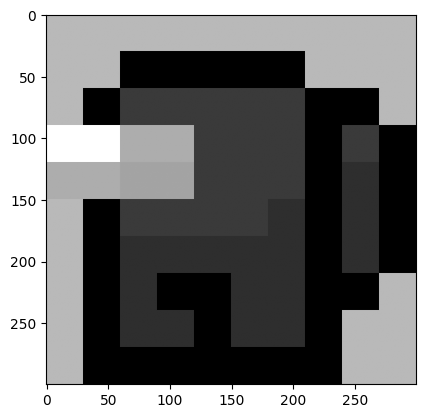

In [ ]:
plt.imshow(image_gray2,cmap='gray')
plt.show()

In [ ]:
# creamos nuestros filtros

kernel_edge_v = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float32)




In [ ]:
filtros = [
    ("bordes verticales",kernel_edge_v)
]

In [ ]:
mapas = []

In [ ]:
for nombre, kernel in filtros:
  img_filtrada = cv2.filter2D(image_gray, ddepth=cv2.CV_32F, kernel=kernel)
  mapas.append((nombre,img_filtrada))

In [ ]:
bordes_v = mapas[0][1]

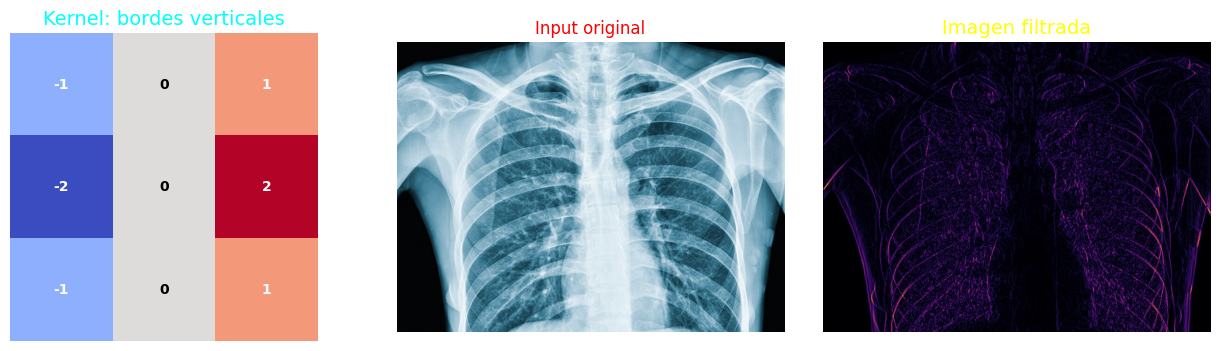

In [ ]:
fig1, axes = plt.subplots(len(filtros), 3, figsize=(16, 4*len(filtros)), squeeze=False)
plt.subplots_adjust(hspace=0.3, wspace=0.1)

for i, (nombre, kernel) in enumerate(filtros):

  ax_k = axes[i, 0]
  ax_k.imshow(kernel, cmap='coolwarm', vmin=-2, vmax=2)
  ax_k.set_title(f"Kernel: {nombre}", color='cyan', fontsize=14)
  for (j, k_val), val in np.ndenumerate(kernel):
      ax_k.text(k_val, j, f"{int(val)}", ha='center', va='center', fontweight='bold',
                color='white' if abs(val) > 0.5 else 'black')
  ax_k.axis('off')

  ax_orig = axes[i, 1]

  ax_orig.imshow(img_rgb, cmap='gray')
  ax_orig.set_title("Input original", color='red')
  ax_orig.axis('off')

  ax_res = axes[i, 2]

  ax_res.imshow(np.abs(mapas[i][1]), cmap='inferno')
  ax_res.set_title(f"Imagen filtrada", color='yellow', fontsize=14)
  ax_res.axis('off')

In [ ]:
mapas2 = []

In [ ]:
for nombre, kernel in filtros:
  img_filtrada2 = cv2.filter2D(image_gray2, ddepth=cv2.CV_32F, kernel=kernel)
  mapas2.append((nombre,img_filtrada2))

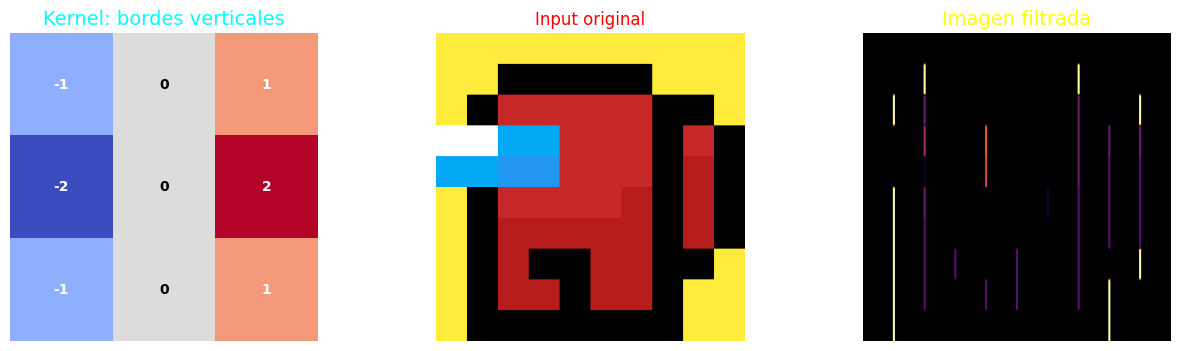

In [ ]:
fig1, axes = plt.subplots(len(filtros), 3, figsize=(16, 4*len(filtros)), squeeze=False)
plt.subplots_adjust(hspace=0.3, wspace=0.1)

for i, (nombre, kernel) in enumerate(filtros):

  ax_k = axes[i, 0]
  ax_k.imshow(kernel, cmap='coolwarm', vmin=-2, vmax=2)
  ax_k.set_title(f"Kernel: {nombre}", color='cyan', fontsize=14)
  for (j, k_val), val in np.ndenumerate(kernel):
      ax_k.text(k_val, j, f"{int(val)}", ha='center', va='center', fontweight='bold',
                color='white' if abs(val) > 0.5 else 'black')
  ax_k.axis('off')

  ax_orig = axes[i, 1]

  ax_orig.imshow(img_rgb2, cmap='gray')
  ax_orig.set_title("Input original", color='red')
  ax_orig.axis('off')

  ax_res = axes[i, 2]

  ax_res.imshow(np.abs(mapas2[i][1]), cmap='inferno')
  ax_res.set_title(f"Imagen filtrada", color='yellow', fontsize=14)
  ax_res.axis('off')

<h1>Pagina de filtros:
https://setosa.io/ev/image-kernels/</h1>